# Reconstruire un capteur de vibration manquant

## L'idée, très simplement

Une vibration est comme une vague qui voyage dans une machine. Les autres capteurs voient une partie de cette vague. Nous voulons donc deviner le signal du capteur absent à partir de ceux qui restent.

**But de recherche :** retrouver le capteur `ACR_Mot.PV` sans l'utiliser comme entrée pendant la reconstruction. Nous masquons son signal seulement dans le Test pour vérifier la méthode honnêtement.

> Important : retrouver la **forme** du mouvement et retrouver sa **hauteur exacte** (l'amplitude) sont deux difficultés différentes. Ce notebook mesure les deux.

## Règles pour une expérience honnête

- Les données sont séparées dans le temps : apprentissage, choix des réglages, puis test final.
- La séparation est faite à l'intérieur de chaque équipement : on ne mélange pas son futur avec son passé.
- Le capteur cible est retiré des mesures utilisées par l'observateur.


In [ ]:
# ============================== CONFIGURATION ==============================
import warnings
warnings.filterwarnings("ignore")

DATA_PATH = r"..\data\processed\preprocessed_data1.csv"   # <-- chemin vers votre CSV (relatif, à adapter)

TIME_COLUMN = "Timestamp"        # nom de la colonne temporelle. Mettre None si pas de colonne temps explicite (index = temps).
TARGET_SENSOR = "ACR_Mot.PV"       # nom du capteur à reconstruire (celui qui sera artificiellement masqué pour l'évaluation)
AVAILABLE_SENSORS = None         # liste des colonnes capteurs à utiliser. None => toutes les colonnes numériques sauf TIME_COLUMN.

# Fraction train / validation / test (split temporel, PAS de shuffle)
TRAIN_FRAC = 0.60
VAL_FRAC   = 0.20
TEST_FRAC  = 0.20   # doit valoir 1 - TRAIN_FRAC - VAL_FRAC

# SSI
SSI_BLOCK_ROWS = 15          # nombre de block-rows "s" (doit être > ordre max testé)
SSI_ORDER_CANDIDATES = [2, 3, 4, 5, 6, 8]   # ordres testés, choisis via validation

# SINDy
SINDY_POLY_DEGREE = 2
SINDY_THRESHOLD_CANDIDATES = [0.01, 0.02, 0.05, 0.1, 0.2]   # sparsité, choisi via validation
SINDY_ALPHA = 0.05

# Kalman / EKF
EKF_Q_SCALE = 1e-3     # covariance de bruit de process (échelle)
EKF_R_SCALE = 1e-2     # covariance de bruit de mesure (échelle)

# Tests de manquants
RANDOM_MISSING_FRACTION = 0.10
CONTINUOUS_WINDOW_FRACTIONS = [0.01, 0.05, 0.10, 0.20, 0.30]
PEAK_WINDOW_HALF_WIDTH = 15     # nb d'échantillons de part et d'autre d'un pic à masquer
LONG_WINDOW_FRACTIONS = [0.30, 0.45, 0.60]

RANDOM_SEED = 42

OUTPUT_DIR = "results_ssi_sindy_ekf"    # dossier où sauver les CSV de résultats (créé s'il n'existe pas)

# =============================================================================
import numpy as np
import pandas as pd
np.random.seed(RANDOM_SEED)

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-6, "Les fractions Train/Val/Test doivent sommer à 1."
print("Configuration chargée.")


Configuration chargée.


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Charger et vérifier les données

On vérifie les colonnes et les valeurs manquantes avant de construire un modèle.


In [6]:
if os.path.exists(DATA_PATH):
    print(f"Chargement des données réelles depuis : {DATA_PATH}")
    df_raw = pd.read_csv(DATA_PATH)
    USING_SYNTHETIC_DATA = False


print("\nDimensions :", df_raw.shape)
print("\nColonnes :", list(df_raw.columns))
print("\nTypes :")
print(df_raw.dtypes)
df_raw.head()


Chargement des données réelles depuis : C:\Users\camelia\Documents\letsgo\industrial-vibration-missing-data-reconstruction\data\processed\preprocessed_data1.csv

Dimensions : (15686, 12)

Colonnes : ['Timestamp', 'equipment_id', 'ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Types :
Timestamp        object
equipment_id     object
ACR_Mot.PV      float64
ACR_Mot.SV      float64
ACR_Mot.TV      float64
ACR_Pmp.PV      float64
ACR_Pmp.SV      float64
ACR_Pmp.TV      float64
Pres.PV         float64
Temp.PV         float64
Barometer       float64
Temperature     float64
dtype: object


,Timestamp,equipment_id,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
0,2024-04-10T12:00:30Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451494,18.061707,1018.053265,20.412823
1,2024-04-10T12:02:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.452516,18.102875,1018.078814,20.385832
2,2024-04-10T12:02:55Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.102875,1018.078814,20.385832
3,2024-04-10T12:03:35Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.078814,20.393339
4,2024-04-10T12:03:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.028774,20.393339


In [7]:

# ============================================================
# Vérifications et préparation des colonnes
# ============================================================

# Vérifier que les colonnes principales existent
assert TIME_COLUMN in df_raw.columns, (
    f"TIME_COLUMN='{TIME_COLUMN}' absent des colonnes : {list(df_raw.columns)}"
)

assert TARGET_SENSOR in df_raw.columns, (
    f"TARGET_SENSOR='{TARGET_SENSOR}' absent des colonnes : {list(df_raw.columns)}"
)


# ============================================================
# Détection automatique de TOUS les capteurs numériques
# ============================================================

if AVAILABLE_SENSORS is None:

    # On récupère toutes les colonnes numériques
    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns.tolist()

    AVAILABLE_SENSORS = numeric_cols

    print("AVAILABLE_SENSORS détecté automatiquement :")
    for col in AVAILABLE_SENSORS:
        print(f"  - {col}")

else:

    # Vérifier que toutes les colonnes demandées existent
    missing_cols = [
        col for col in AVAILABLE_SENSORS
        if col not in df_raw.columns
    ]

    assert not missing_cols, (
        f"Colonnes absentes du DataFrame : {missing_cols}"
    )


# ============================================================
# Vérifier que le capteur cible est bien disponible
# ============================================================

assert TARGET_SENSOR in AVAILABLE_SENSORS, (
    f"TARGET_SENSOR='{TARGET_SENSOR}' doit faire partie "
    f"de AVAILABLE_SENSORS"
)


# ============================================================
# Séparer le capteur cible des autres capteurs
# ============================================================

OTHER_SENSORS = [
    col for col in AVAILABLE_SENSORS
    if col != TARGET_SENSOR
]


print("\n==============================================")
print("Configuration des capteurs")
print("==============================================")

print(f"Capteur cible (à reconstruire) : {TARGET_SENSOR}")

print(f"\nNombre de capteurs disponibles : {len(AVAILABLE_SENSORS)}")

print("Tous les capteurs numériques :")
for col in AVAILABLE_SENSORS:
    print(f"  - {col}")

print(f"\nNombre de capteurs utilisés comme prédicteurs : {len(OTHER_SENSORS)}")

print("Autres capteurs :")
for col in OTHER_SENSORS:
    print(f"  - {col}")


# ============================================================
# Vérification des valeurs manquantes
# ============================================================

print("\n==============================================")
print("Valeurs manquantes par colonne")
print("==============================================")

print(df_raw[AVAILABLE_SENSORS].isna().sum())


# ============================================================
# Statistiques descriptives
# ============================================================

print("\n==============================================")
print("Statistiques descriptives")
print("==============================================")

display(df_raw[AVAILABLE_SENSORS].describe())


# ============================================================
# Vérification finale des colonnes originales
# ============================================================

print("\n==============================================")
print("Colonnes originales du DataFrame")
print("==============================================")

print(df_raw.columns.tolist())

print(f"\nNombre total de colonnes : {len(df_raw.columns)}")
print(f"Nombre de colonnes numériques : {len(AVAILABLE_SENSORS)}")



AVAILABLE_SENSORS détecté automatiquement :
  - ACR_Mot.PV
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Configuration des capteurs
Capteur cible (à reconstruire) : ACR_Mot.PV

Nombre de capteurs disponibles : 10
Tous les capteurs numériques :
  - ACR_Mot.PV
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Nombre de capteurs utilisés comme prédicteurs : 9
Autres capteurs :
  - ACR_Mot.SV
  - ACR_Mot.TV
  - ACR_Pmp.PV
  - ACR_Pmp.SV
  - ACR_Pmp.TV
  - Pres.PV
  - Temp.PV
  - Barometer
  - Temperature

Valeurs manquantes par colonne
ACR_Mot.PV     0
ACR_Mot.SV     0
ACR_Mot.TV     0
ACR_Pmp.PV     0
ACR_Pmp.SV     0
ACR_Pmp.TV     0
Pres.PV        0
Temp.PV        0
Barometer      0
Temperature    0
dtype: int64

Statistiques descriptives


,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
count,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000,15686.000000
mean,0.002185,13.710205,33.592024,0.002872,21.629912,33.777091,36.395911,33.472410,1017.903602,23.884231
std,0.000980,9.932659,10.214518,0.001310,14.912302,6.425036,13.472976,8.710358,4.266254,1.537564
min,0.000533,0.387957,17.718750,0.000255,0.413133,17.609375,0.424722,18.061707,1010.347385,19.007975
25%,0.001197,0.506138,24.203125,0.001091,0.566808,30.023438,39.183369,25.818359,1012.060680,23.415518
50%,0.002650,15.169131,32.054688,0.003649,30.162298,35.320312,40.302795,33.243469,1020.280371,24.288061
75%,0.003018,19.126297,43.328125,0.003838,33.887039,39.117188,42.824001,41.783844,1020.921440,24.775757
max,0.003945,30.173618,54.296875,0.004244,42.875000,44.609375,46.708912,55.039612,1022.532339,26.970425



Colonnes originales du DataFrame
['Timestamp', 'equipment_id', 'ACR_Mot.PV', 'ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']

Nombre total de colonnes : 12
Nombre de colonnes numériques : 10


## 2. Voir les liens entre les capteurs

Si plusieurs capteurs évoluent ensemble, ils peuvent contenir une information utile sur le capteur absent. Une corrélation n'est pas une preuve de causalité : elle sert ici à rechercher de la redondance de mesure.


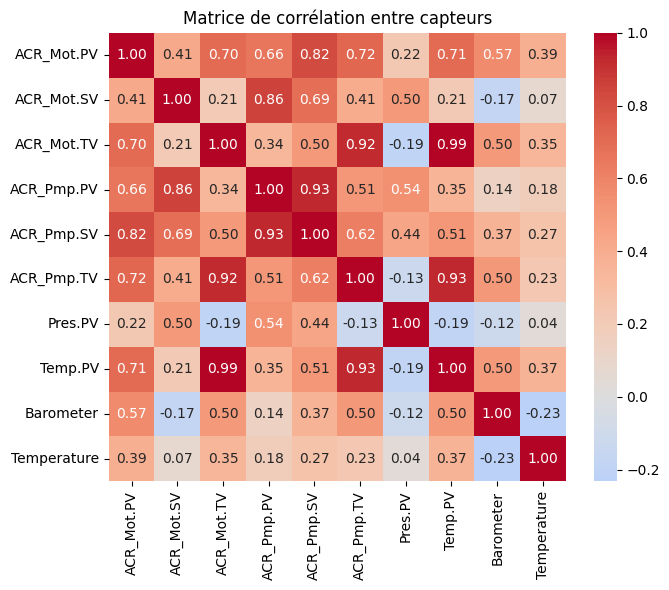


Corrélation avec le capteur cible :
ACR_Mot.PV     1.000000
ACR_Pmp.SV     0.819425
ACR_Pmp.TV     0.718699
Temp.PV        0.711069
ACR_Mot.TV     0.702032
ACR_Pmp.PV     0.659238
Barometer      0.570204
ACR_Mot.SV     0.414567
Temperature    0.385677
Pres.PV        0.224215
Name: ACR_Mot.PV, dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(7,6))
corr = df_raw[AVAILABLE_SENSORS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation entre capteurs")
plt.tight_layout()
plt.show()
print("\nCorrélation avec le capteur cible :")
print(corr[TARGET_SENSOR].sort_values(ascending=False))


### Conclusion

L’analyse du capteur **ACR_Mot.PV** met en évidence trois propriétés importantes pour la reconstruction des données manquantes :

* **Une forte dépendance temporelle** : l’autocorrélation reste élevée jusqu’à 100 lags, ce qui indique que les valeurs actuelles du capteur sont fortement liées à son historique. L’information temporelle peut donc être exploitée pour estimer les valeurs manquantes.

* **Une dynamique non stationnaire** : la variance glissante présente plusieurs périodes de forte augmentation, notamment autour de 9 000–10 500 points. Le comportement du capteur varie donc selon le régime de fonctionnement de l’équipement. Une méthode de reconstruction doit ainsi être capable de s’adapter aux changements de régime plutôt que de supposer une dynamique constante.

* **Une information complémentaire provenant des autres capteurs** : ACR_Mot.PV est fortement corrélé avec plusieurs variables, notamment **ACR_Pmp.SV (0,82)**, **ACR_Pmp.TV (0,72)**, **ACR_Mot.TV (0,70)** et **Temp.PV (0,71)**. Ces capteurs peuvent donc fournir des informations utiles lorsque le signal cible devient indisponible.

Ainsi, les données présentent à la fois une **structure temporelle forte** et une **dépendance multivariée entre capteurs**. Cela confirme que la reconstruction de **ACR_Mot.PV** peut être abordée comme un problème de **reconstruction spatio-temporelle**, en combinant l’historique du signal et les informations des autres capteurs. Les variations importantes de variance montrent également que l’évaluation du modèle doit être réalisée sur différents scénarios de perte de données, notamment des pertes aléatoires, des fenêtres continues et des périodes de forte variation du signal.

## 3. Découpage temporel par équipement

Chaque machine garde son ordre temporel. Le modèle apprend sur le passé, les réglages sont choisis sur la validation, et le Test reste intact jusqu'à la fin.


TRAIN
equipment_id
A    6205
B    3163
C      42
Name: count, dtype: int64

VALIDATION
equipment_id
A    2068
B    1054
C      14
Name: count, dtype: int64

TEST
equipment_id
A    2069
B    1056
C      15
Name: count, dtype: int64


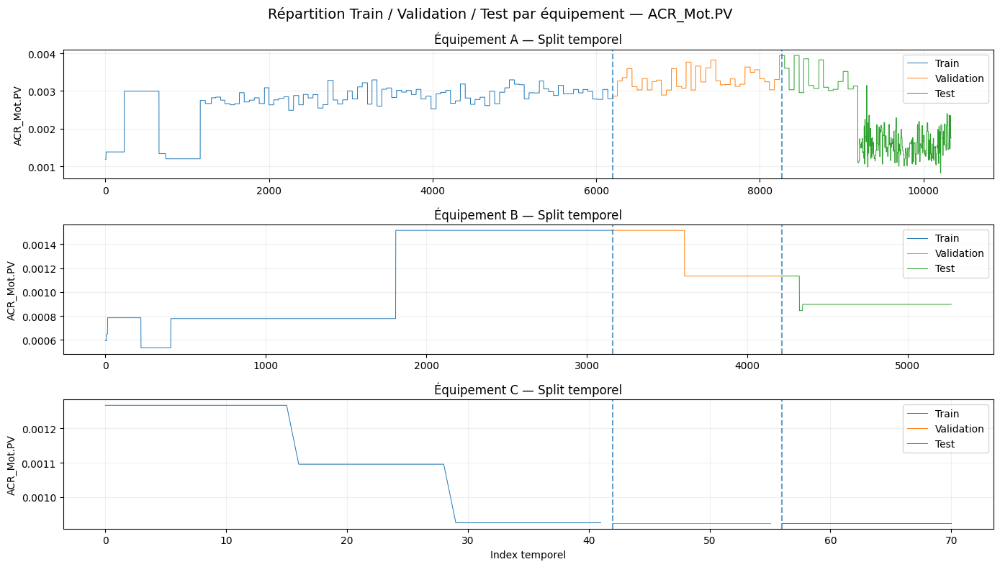

In [9]:
# ============================================================
# 1. Split temporel PAR ÉQUIPEMENT
# ============================================================

TRAIN_FRAC = 0.60
VAL_FRAC   = 0.20
TEST_FRAC  = 0.20

train_list = []
val_list   = []
test_list  = []

for equipment in df_raw["equipment_id"].unique():

    df_eq = (
        df_raw[df_raw["equipment_id"] == equipment]
        .sort_index()
        .reset_index(drop=True)
    )

    N = len(df_eq)

    n_train = int(N * TRAIN_FRAC)
    n_val   = int(N * VAL_FRAC)

    # Train
    train_eq = df_eq.iloc[:n_train].copy()

    # Validation
    val_eq = df_eq.iloc[n_train:n_train+n_val].copy()

    # Test
    test_eq = df_eq.iloc[n_train+n_val:].copy()

    train_list.append(train_eq)
    val_list.append(val_eq)
    test_list.append(test_eq)


# ============================================================
# 2. Reconstruction des DataFrames
# ============================================================

df_train = pd.concat(train_list, ignore_index=True)
df_val   = pd.concat(val_list, ignore_index=True)
df_test  = pd.concat(test_list, ignore_index=True)


# ============================================================
# 3. Vérification
# ============================================================

print("TRAIN")
print(df_train["equipment_id"].value_counts())

print("\nVALIDATION")
print(df_val["equipment_id"].value_counts())

print("\nTEST")
print(df_test["equipment_id"].value_counts())

import matplotlib.pyplot as plt

# ============================================================
# Visualisation du split temporel par équipement
# ============================================================

equipments = sorted(df_raw["equipment_id"].unique())

fig, axes = plt.subplots(
    len(equipments), 1,
    figsize=(14, 8),
    sharex=False
)

if len(equipments) == 1:
    axes = [axes]

for ax, equipment in zip(axes, equipments):

    # Données de cet équipement
    train_eq = df_train[
        df_train["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    val_eq = df_val[
        df_val["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    test_eq = df_test[
        df_test["equipment_id"] == equipment
    ][TARGET_SENSOR].reset_index(drop=True)

    # Indices temporels
    train_idx = range(len(train_eq))

    val_idx = range(
        len(train_eq),
        len(train_eq) + len(val_eq)
    )

    test_idx = range(
        len(train_eq) + len(val_eq),
        len(train_eq) + len(val_eq) + len(test_eq)
    )

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------
    ax.plot(
        train_idx,
        train_eq,
        label="Train",
        lw=0.7
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------
    ax.plot(
        val_idx,
        val_eq,
        label="Validation",
        lw=0.7
    )

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------
    ax.plot(
        test_idx,
        test_eq,
        label="Test",
        lw=0.7
    )

    # Séparations
    ax.axvline(
        len(train_eq),
        linestyle="--",
        alpha=0.7
    )

    ax.axvline(
        len(train_eq) + len(val_eq),
        linestyle="--",
        alpha=0.7
    )

    ax.set_title(
        f"Équipement {equipment} — Split temporel"
    )

    ax.set_ylabel(TARGET_SENSOR)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")


axes[-1].set_xlabel("Index temporel")

fig.suptitle(
    f"Répartition Train / Validation / Test par équipement — {TARGET_SENSOR}",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [10]:
# Scaling : le scaler est ajusté UNIQUEMENT sur Train (évite le data leakage)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(df_train[AVAILABLE_SENSORS].values)

def scale(dframe):
    return pd.DataFrame(scaler.transform(dframe[AVAILABLE_SENSORS].values), columns=AVAILABLE_SENSORS)

train_s = scale(df_train)
val_s   = scale(df_val)
test_s  = scale(df_test)

target_idx = AVAILABLE_SENSORS.index(TARGET_SENSOR)
obs_idx    = [AVAILABLE_SENSORS.index(c) for c in OTHER_SENSORS]

print("Scaler ajusté sur Train uniquement (moyenne/écart-type) :")
print(pd.DataFrame({"mean": scaler.mean_, "scale": scaler.scale_}, index=AVAILABLE_SENSORS))


Scaler ajusté sur Train uniquement (moyenne/écart-type) :
                    mean      scale
ACR_Mot.PV      0.002144   0.000914
ACR_Mot.SV     13.341657   9.494807
ACR_Mot.TV     30.218471   7.837434
ACR_Pmp.PV      0.002945   0.001260
ACR_Pmp.SV     22.657275  15.147921
ACR_Pmp.TV     31.971461   5.751887
Pres.PV        38.712266  10.644683
Temp.PV        30.833419   6.699289
Barometer    1017.199133   4.556650
Temperature    24.322916   0.895609


In [11]:
corr_with_target = df_train[AVAILABLE_SENSORS].corr()[TARGET_SENSOR].drop(TARGET_SENSOR).sort_values(key=abs, ascending=False)
print("Corrélation (Train) des capteurs disponibles avec la cible, triée par |corr| :")
print(corr_with_target)

SENSOR_CORR_MIN_THRESHOLD = 0.0   # mettre par ex. 0.05 pour exclure les capteurs quasi-non-corrélés
selected_sensors = [c for c in OTHER_SENSORS if abs(corr_with_target.get(c, 1.0)) >= SENSOR_CORR_MIN_THRESHOLD]
print(f"\nCapteurs retenus pour SSI ({len(selected_sensors)}) :", selected_sensors)

ALL_SSI_SENSORS = [TARGET_SENSOR] + [c for c in selected_sensors]  # cible incluse en Train pour identifier C_missing


Corrélation (Train) des capteurs disponibles avec la cible, triée par |corr| :
ACR_Pmp.SV     0.868289
ACR_Pmp.TV     0.862675
Temp.PV        0.804388
ACR_Mot.TV     0.758836
Barometer      0.754261
ACR_Pmp.PV     0.726760
ACR_Mot.SV     0.424982
Pres.PV        0.229944
Temperature   -0.093339
Name: ACR_Mot.PV, dtype: float64

Capteurs retenus pour SSI (9) : ['ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']


## 4. SSI : trouver l'état caché de la machine

SSI résume les mouvements communs vus par tous les capteurs dans quelques variables cachées. C'est utile car les vibrations se propagent : une même dynamique peut laisser une trace à plusieurs endroits.


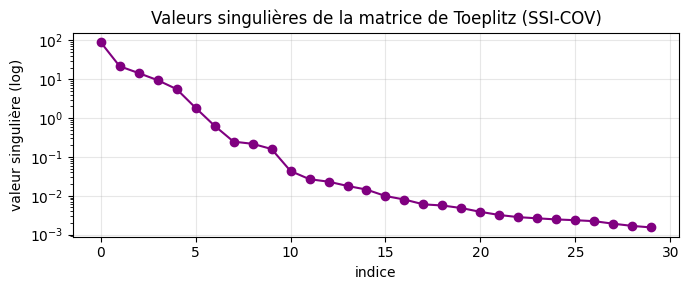

In [12]:
def ssi_cov(Y, s, order):
    '''SSI covariance-driven. Y: (N, m). Retourne A (n,n), C (m,n), valeurs singulières.'''
    N, m = Y.shape
    Yc = Y - Y.mean(axis=0, keepdims=True)
    max_lag = 2 * s
    R = np.zeros((max_lag, m, m))
    for i in range(max_lag):
        R[i] = (Yc[i:].T @ Yc[:N - i]) / (N - i)
    T = np.zeros((s * m, s * m))
    for i in range(s):
        for j in range(s):
            lag = i + j + 1
            T[i*m:(i+1)*m, j*m:(j+1)*m] = R[min(lag, max_lag - 1)]
    U, Sv, Vt = np.linalg.svd(T)
    U1 = U[:, :order]
    S1 = Sv[:order]
    O = U1 @ np.diag(np.sqrt(np.maximum(S1, 1e-12)))
    C = O[:m, :]
    A = np.linalg.pinv(O[:-m, :]) @ O[m:, :]
    return A, C, Sv


def ssi_observability(C, A, s):
    order = A.shape[0]
    blocks = [C]
    Ak = np.eye(order)
    for _ in range(1, s):
        Ak = Ak @ A
        blocks.append(C @ Ak)
    return np.vstack(blocks)


def ssi_estimate_states(Y, C, A, s):
    '''Estime la séquence d'état latent par projection sur la matrice d'observabilité.'''
    N, m = Y.shape
    O = ssi_observability(C, A, s)
    O_pinv = np.linalg.pinv(O)
    n_out = N - s + 1
    X = np.zeros((n_out, A.shape[0]))
    for k in range(n_out):
        X[k] = O_pinv @ Y[k:k+s].reshape(-1)
    return X

Y_train_full = train_s[ALL_SSI_SENSORS].values   # cible incluse en Train (pour connaître C_missing)

# --- Valeurs singulières pour aider au choix de l'ordre ---
_, _, Sv_full = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, max(SSI_ORDER_CANDIDATES))
fig, ax = plt.subplots(figsize=(7,3))
ax.semilogy(Sv_full[:30], "o-", color="purple")
ax.set_xlabel("indice")
ax.set_ylabel("valeur singulière (log)")
ax.set_title("Valeurs singulières de la matrice de Toeplitz (SSI-COV)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
# --- Sélection de l'ordre du modèle sur Validation : erreur de reconstruction one-step-ahead ---
def one_step_ahead_error(A, C, s, Y):
    X = ssi_estimate_states(Y, C, A, s)
    Ypred = X[:-1] @ (C @ A).T   # y_{k+1} approx C A x_k  (à un décalage près de la fenêtre s)
    Ytrue_shift = Y[s: s + Ypred.shape[0]]
    n_cmp = min(len(Ypred), len(Ytrue_shift))
    return np.sqrt(np.mean((Ypred[:n_cmp] - Ytrue_shift[:n_cmp])**2))

val_errors = {}
Y_val_full = val_s[ALL_SSI_SENSORS].values
for order in SSI_ORDER_CANDIDATES:
    try:
        A_o, C_o, _ = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, order)
        err = one_step_ahead_error(A_o, C_o, SSI_BLOCK_ROWS, Y_val_full)
        val_errors[order] = err
    except Exception as e:
        val_errors[order] = np.inf
        print(f"Ordre {order} : échec ({e})")

print("Erreur de reconstruction one-step-ahead (Validation) par ordre :")
for o, e in val_errors.items():
    print(f"  ordre={o:2d}  RMSE_val={e:.4f}")

SSI_ORDER = min(val_errors, key=val_errors.get)
print(f"\n>>> Ordre retenu (minimise l'erreur de Validation) : n = {SSI_ORDER}")

A, C_ssi, Sv = ssi_cov(Y_train_full, SSI_BLOCK_ROWS, SSI_ORDER)
print("\nMatrice A (dynamique discrète latente) :")
print(np.round(A, 4))
print("\nMatrice C (capteurs = fonction de l'état latent), lignes = [cible] + capteurs dispo :")
print(pd.DataFrame(np.round(C_ssi, 3), index=ALL_SSI_SENSORS, columns=[f"x{i+1}" for i in range(SSI_ORDER)]))

C_target_row = C_ssi[0:1, :]                 # ligne correspondant au capteur cible
C_obs_full   = C_ssi[1:, :]                   # lignes correspondant aux capteurs disponibles (ordre = selected_sensors)


Erreur de reconstruction one-step-ahead (Validation) par ordre :
  ordre= 2  RMSE_val=0.4376
  ordre= 3  RMSE_val=0.3711
  ordre= 4  RMSE_val=0.3405
  ordre= 5  RMSE_val=0.2144
  ordre= 6  RMSE_val=0.1815
  ordre= 8  RMSE_val=0.1614

>>> Ordre retenu (minimise l'erreur de Validation) : n = 8

Matrice A (dynamique discrète latente) :
[[ 9.990e-01 -5.000e-04  7.000e-04 -3.000e-04  0.000e+00  6.000e-04
  -1.000e-04  3.000e-04]
 [-9.000e-04  9.988e-01 -3.000e-04  4.000e-04 -2.000e-04 -2.000e-04
  -3.300e-03  1.000e-03]
 [ 1.800e-03  1.400e-03  9.939e-01  4.000e-04 -2.600e-03 -1.700e-03
  -6.400e-03  1.000e-04]
 [ 1.200e-03  1.200e-03 -1.500e-03  9.971e-01  5.000e-04 -1.000e-04
   2.500e-03  1.200e-03]
 [ 9.000e-04  2.000e-04 -1.200e-03  1.600e-03  9.977e-01 -2.600e-03
  -1.500e-03  1.500e-03]
 [ 6.000e-04  8.000e-04 -7.000e-04  3.000e-04 -7.000e-04  9.917e-01
  -4.100e-03  1.900e-03]
 [ 1.800e-03  1.700e-03 -7.500e-03  6.000e-04  1.000e-04 -1.400e-03
   9.812e-01 -2.900e-03]
 [-3.000e-04 -

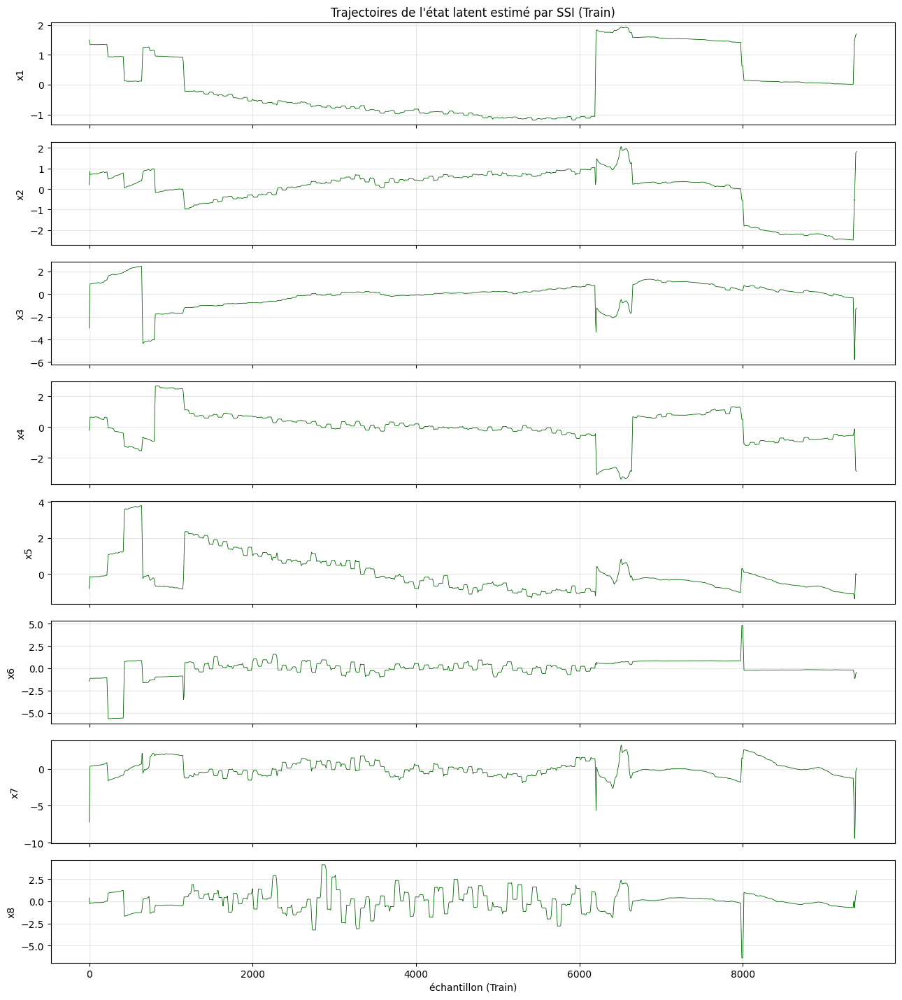

In [14]:
# --- Trajectoires de l'état latent estimé (sur Train) ---
X_train_hat = ssi_estimate_states(Y_train_full, C_ssi, A, SSI_BLOCK_ROWS)
X_val_hat = ssi_estimate_states(Y_val_full, C_ssi, A, SSI_BLOCK_ROWS)

fig, axes = plt.subplots(SSI_ORDER, 1, figsize=(13, 1.8*SSI_ORDER), sharex=True)
if SSI_ORDER == 1:
    axes = [axes]
for i, ax in enumerate(axes):
    ax.plot(X_train_hat[:, i], lw=0.6, color="darkgreen")
    ax.set_ylabel(f"x{i+1}")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("échantillon (Train)")
axes[0].set_title("Trajectoires de l'état latent estimé par SSI (Train)")
plt.tight_layout()
plt.show()


## 5. SINDy : écrire une règle courte pour le mouvement

SINDy cherche une règle mathématique simple pour l'évolution de l'état caché. Son avantage attendu est de pouvoir avancer quand le capteur manque. Nous gardons seulement un modèle stable sur la validation.


In [15]:
# Pas de temps représentatif entre deux observations.
# Si aucun temps exploitable n'est disponible, on travaille en pas d'échantillonnage.
if TIME_COLUMN is not None:
    _times = pd.to_datetime(df_train[TIME_COLUMN], errors="coerce", utc=True)
    DT_APPROX = _times.diff().dt.total_seconds().median()
else:
    DT_APPROX = 1.0
if not np.isfinite(DT_APPROX) or DT_APPROX <= 0:
    DT_APPROX = 1.0
print(f"Pas de temps utilisé : {DT_APPROX:.6f} s")


Pas de temps utilisé : 1.000000 s




NORMALISATION DES ÉTATS SSI
Train : (9396, 8)
Validation : (3122, 8)

Moyenne Train :
[ 4.26726910e-15  5.23917507e-16  6.64054214e-18 -5.66218469e-16
  2.61363748e-15 -8.92077670e-16 -2.05393032e-16  3.05512202e-16]

Écart-type Train :
[1. 1. 1. 1. 1. 1. 1. 1.]


COMPARAISON SINDy : DEGRÉ 2 VS DEGRÉ 3


========== DEGRÉ 2 ==========

Degree = 2 | Threshold = 0.001
⚠️ SINDy : 1 états hors domaine. Max = 5.0595
⚠️ SINDy : 1 états hors domaine. Max = 5.3891
⚠️ SINDy : 1 états hors domaine. Max = 5.4556
⚠️ SINDy : 1 états hors domaine. Max = 5.5341
⚠️ SINDy : 1 états hors domaine. Max = 5.5280
⚠️ SINDy : 1 états hors domaine. Max = 5.6724
⚠️ SINDy : 1 états hors domaine. Max = 5.7523
⚠️ SINDy : 1 états hors domaine. Max = 6.1729
⚠️ SINDy : 1 états hors domaine. Max = 6.2624
⚠️ SINDy : 1 états hors domaine. Max = 6.3644
⚠️ SINDy : 1 états hors domaine. Max = 6.3522
⚠️ SINDy : 1 états hors domaine. Max = 6.5419
⚠️ SINDy : 1 états hors domaine. Max = 6.6506
⚠️ SINDy : 1 états hors domaine.

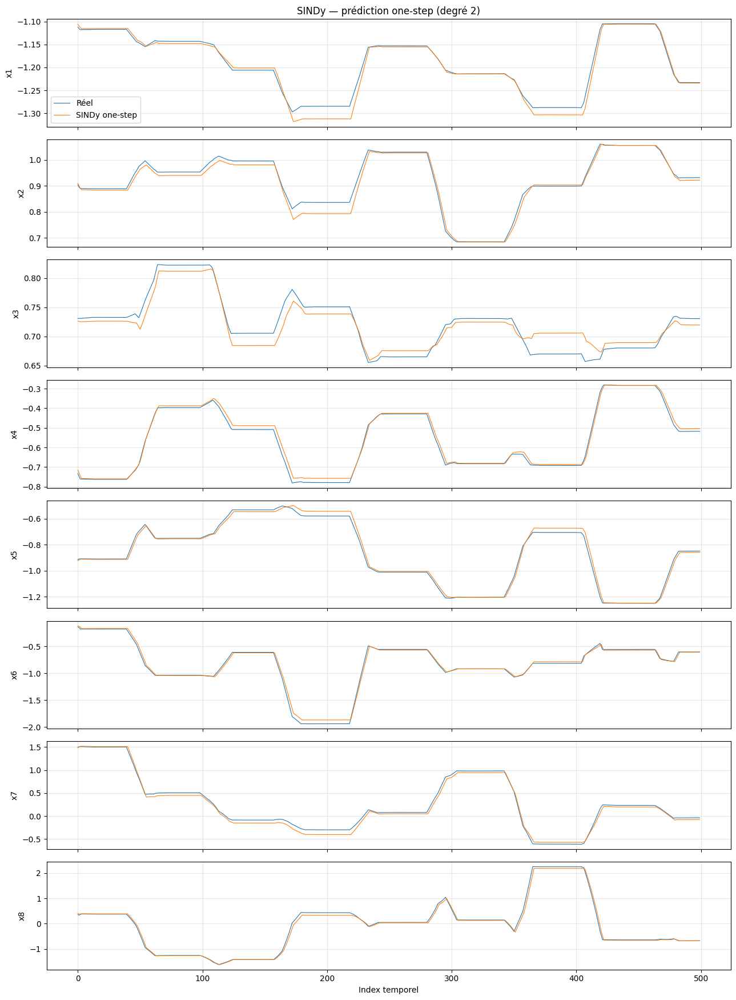

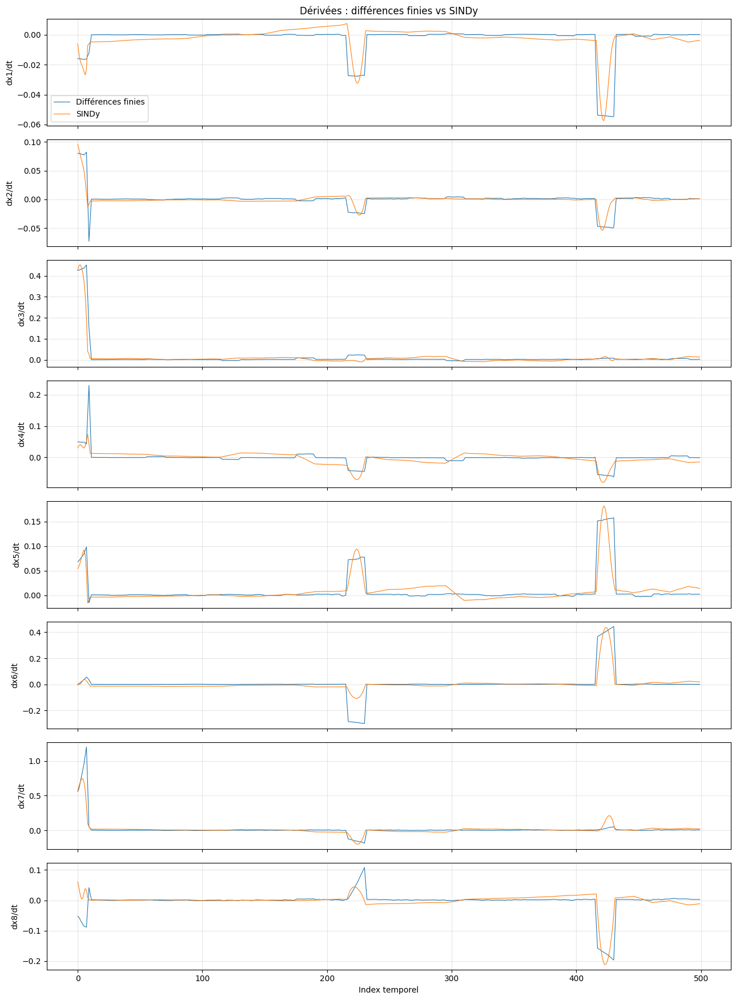



COMPARAISON DES DEGRÉS
 degree  threshold  one_step_RMSE  active_terms  max_abs_coef  stable
      2       0.05       0.023009             0           0.0    True
      3       0.05       0.023009             0           0.0    True


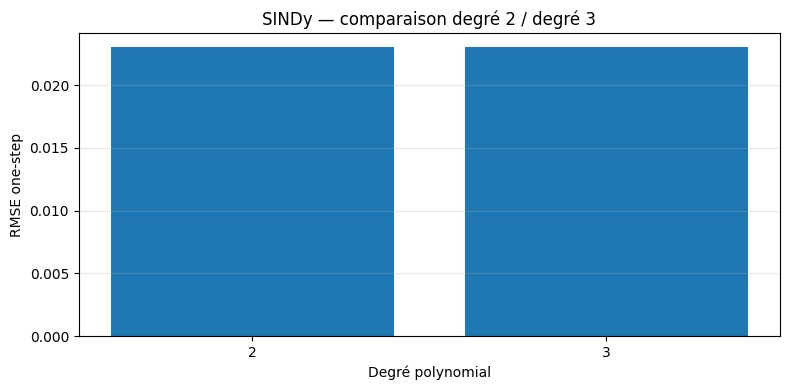



TEST DE STABILITÉ FINAL
⚠️ SINDy : 1 états hors domaine. Max = 5.0595
⚠️ SINDy : 1 états hors domaine. Max = 5.3891
⚠️ SINDy : 1 états hors domaine. Max = 5.4556
⚠️ SINDy : 1 états hors domaine. Max = 5.5341
⚠️ SINDy : 1 états hors domaine. Max = 5.5280
⚠️ SINDy : 1 états hors domaine. Max = 5.6724
⚠️ SINDy : 1 états hors domaine. Max = 5.7523
⚠️ SINDy : 1 états hors domaine. Max = 6.1729
⚠️ SINDy : 1 états hors domaine. Max = 6.2624
⚠️ SINDy : 1 états hors domaine. Max = 6.3644
⚠️ SINDy : 1 états hors domaine. Max = 6.3522
⚠️ SINDy : 1 états hors domaine. Max = 6.5419
⚠️ SINDy : 1 états hors domaine. Max = 6.6506
⚠️ SINDy : 1 états hors domaine. Max = 7.2382
⚠️ SINDy : 1 états hors domaine. Max = 7.3723
⚠️ SINDy : 1 états hors domaine. Max = 7.5194
⚠️ SINDy : 1 états hors domaine. Max = 7.4949
⚠️ SINDy : 1 états hors domaine. Max = 6.5133
⚠️ SINDy : 1 états hors domaine. Max = 6.6039
⚠️ SINDy : 1 états hors domaine. Max = 7.0850
⚠️ SINDy : 1 états hors domaine. Max = 7.1898
⚠️ SINDy

In [16]:
# ============================================================
# SINDy — VERSION AMÉLIORÉE
# ============================================================
#
# Train :
#   Identification du modèle
#
# Validation :
#   Choix du degré + threshold
#   One-step prediction
#   Test de stabilité
#
# Test :
#   NON utilisé ici
#
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations_with_replacement
from sklearn.preprocessing import StandardScaler
from scipy.integrate import solve_ivp


# ============================================================
# 1. PARAMÈTRES SINDy
# ============================================================

# Degrés à comparer
SINDY_POLY_DEGREES = [2, 3]

# Degré par défaut
SINDY_POLY_DEGREE = 3

# Régularisation Ridge
SINDY_ALPHA = 0.05

# Thresholds testés
SINDY_THRESHOLD_CANDIDATES = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.05,
    0.1,
    0.2
]

# Fonctions trigonométriques
SINDY_INCLUDE_TRIG = True


# ============================================================
# 2. PARAMÈTRES DE STABILITÉ
# ============================================================

# Limite des états normalisés
SINDY_STATE_LIMIT = 5.0

# Nombre de points utilisés pour le test
# de simulation libre courte
SINDY_STABILITY_STEPS = 300


# ============================================================
# 3. NORMALISATION DES ÉTATS SSI
# ============================================================
#
# IMPORTANT :
# Le scaler est entraîné UNIQUEMENT sur Train.
#
# X_train_hat et X_val_hat restent inchangés.
# ============================================================

SINDY_SCALER = StandardScaler()


# Fit + transform TRAIN
X_train_hat_sindy = (
    SINDY_SCALER.fit_transform(
        X_train_hat
    )
)


# Transform VALIDATION
X_val_hat_sindy = (
    SINDY_SCALER.transform(
        X_val_hat
    )
)


print("\n")
print("=" * 60)
print("NORMALISATION DES ÉTATS SSI")
print("=" * 60)

print(
    "Train :",
    X_train_hat_sindy.shape
)

print(
    "Validation :",
    X_val_hat_sindy.shape
)

print("\nMoyenne Train :")

print(
    np.mean(
        X_train_hat_sindy,
        axis=0
    )
)

print("\nÉcart-type Train :")

print(
    np.std(
        X_train_hat_sindy,
        axis=0
    )
)


# ============================================================
# 4. BIBLIOTHÈQUE SINDy
# ============================================================

def build_library(
    X,
    degree=3,
    feature_names=None,
    include_trig=True
):

    """
    Bibliothèque :

    1
    x1, x2, ...
    x1², x1x2, ...
    x1³, x1²x2, ...
    sin(x1), cos(x1), ...
    """

    X = np.asarray(
        X,
        dtype=float
    )


    if X.ndim == 1:

        X = X.reshape(
            -1,
            1
        )


    n_samples, n_features = (
        X.shape
    )


    # --------------------------------------------------------
    # Noms des variables
    # --------------------------------------------------------

    if feature_names is None:

        feature_names = [
            f"x{i+1}"
            for i in range(
                n_features
            )
        ]


    cols = []
    names = []


    # --------------------------------------------------------
    # Constante
    # --------------------------------------------------------

    cols.append(
        np.ones(
            n_samples
        )
    )

    names.append(
        "1"
    )


    # --------------------------------------------------------
    # Termes polynomiaux
    # --------------------------------------------------------

    for deg in range(
        1,
        degree + 1
    ):

        for comb in combinations_with_replacement(
            range(n_features),
            deg
        ):

            term = np.ones(
                n_samples
            )

            name_parts = []


            for i in comb:

                term *= X[:, i]

                name_parts.append(
                    feature_names[i]
                )


            cols.append(
                term
            )


            if deg == 1:

                name = name_parts[0]

            else:

                name = " ".join(
                    name_parts
                )


            names.append(
                name
            )


    # --------------------------------------------------------
    # Sin / Cos
    # --------------------------------------------------------

    if include_trig:

        for i in range(
            n_features
        ):

            cols.append(
                np.sin(
                    X[:, i]
                )
            )

            names.append(
                f"sin({feature_names[i]})"
            )


            cols.append(
                np.cos(
                    X[:, i]
                )
            )

            names.append(
                f"cos({feature_names[i]})"
            )


    Theta = np.column_stack(
        cols
    )


    return Theta, names


# ============================================================
# 5. STLSQ
# ============================================================

def stlsq(
    Theta,
    Xdot,
    threshold,
    alpha,
    max_iter=20
):

    """
    Sequential Thresholded Least Squares
    avec régularisation Ridge.
    """

    Theta = np.asarray(
        Theta,
        dtype=float
    )

    Xdot = np.asarray(
        Xdot,
        dtype=float
    )


    n_library = (
        Theta.shape[1]
    )

    n_states = (
        Xdot.shape[1]
    )


    # --------------------------------------------------------
    # Régression Ridge initiale
    # --------------------------------------------------------

    A = (
        Theta.T @ Theta
        + alpha
        * np.eye(
            n_library
        )
    )


    B = (
        Theta.T @ Xdot
    )


    Xi = np.linalg.solve(
        A,
        B
    )


    # --------------------------------------------------------
    # STLSQ
    # --------------------------------------------------------

    for k in range(
        n_states
    ):

        active = np.ones(
            n_library,
            dtype=bool
        )


        for _ in range(
            max_iter
        ):

            if active.sum() == 0:

                Xi[:, k] = 0.0

                break


            small = (
                np.abs(
                    Xi[
                        active,
                        k
                    ]
                )
                < threshold
            )


            if not small.any():

                break


            active_indices = (
                np.where(active)[0]
            )


            active[
                active_indices[
                    small
                ]
            ] = False


            if active.sum() == 0:

                Xi[:, k] = 0.0

                break


            Theta_active = (
                Theta[:, active]
            )


            A_active = (
                Theta_active.T
                @ Theta_active
                + alpha
                * np.eye(
                    active.sum()
                )
            )


            B_active = (
                Theta_active.T
                @ Xdot[:, k]
            )


            Xi[:, k] = 0.0


            Xi[
                active,
                k
            ] = np.linalg.solve(
                A_active,
                B_active
            )


    return Xi


# ============================================================
# 6. CLASSE SimpleSINDy
# ============================================================

class SimpleSINDy:

    def __init__(
        self,
        degree=3,
        threshold=0.05,
        alpha=0.05,
        include_trig=True
    ):

        self.degree = degree

        self.threshold = (
            threshold
        )

        self.alpha = alpha

        self.include_trig = (
            include_trig
        )

        self.feature_names = None

        self.lib_names = None

        self.Xi = None

        self.n_states = None


    # ========================================================
    # FIT
    # ========================================================

    def fit(
        self,
        X,
        t,
        feature_names=None
    ):

        X = np.asarray(
            X,
            dtype=float
        )

        t = np.asarray(
            t,
            dtype=float
        )


        if X.ndim == 1:

            X = X.reshape(
                -1,
                1
            )


        self.n_states = (
            X.shape[1]
        )


        if feature_names is None:

            feature_names = [
                f"x{i+1}"
                for i in range(
                    self.n_states
                )
            ]


        self.feature_names = (
            feature_names
        )


        # ----------------------------------------------------
        # Dérivée par différences finies
        # ----------------------------------------------------

        Xdot = np.gradient(
            X,
            t,
            axis=0
        )


        # ----------------------------------------------------
        # Bibliothèque
        # ----------------------------------------------------

        Theta, self.lib_names = (
            build_library(
                X,
                degree=self.degree,
                feature_names=(
                    self.feature_names
                ),
                include_trig=(
                    self.include_trig
                )
            )
        )


        # ----------------------------------------------------
        # Identification
        # ----------------------------------------------------

        self.Xi = stlsq(
            Theta,
            Xdot,
            threshold=self.threshold,
            alpha=self.alpha
        )


        return self


    # ========================================================
    # PREDICT
    # ========================================================

    def predict(
        self,
        X
    ):

        X = np.asarray(
            X,
            dtype=float
        )

        one_sample = False

        if X.ndim == 1:

            X = X.reshape(
                1,
                -1
            )

            one_sample = True

        # ========================================================
        # 1. Vérification des états
        # ========================================================

        if not np.all(
            np.isfinite(X)
        ):
            raise RuntimeError(
                "SINDy reçoit des états non finis."
            )

        # --------------------------------------------------------
        # Détection hors domaine
        # --------------------------------------------------------

        ood_mask = np.any(
            np.abs(X) > SINDY_STATE_LIMIT,
            axis=1
        )

        if np.any(ood_mask):

            max_state = np.max(
                np.abs(X[ood_mask])
            )

            print(
                f"⚠️ SINDy : "
                f"{ood_mask.sum()} états hors domaine. "
                f"Max = {max_state:.4f}"
            )

        # ========================================================
        # 2. Construction bibliothèque
        # ========================================================

        Theta, _ = build_library(
            X,
            degree=self.degree,
            feature_names=self.feature_names,
            include_trig=self.include_trig
        )

        # ========================================================
        # 3. Dynamique SINDy
        # ========================================================

        Xdot = (
            Theta @ self.Xi
        )

        # ========================================================
        # 4. Vérification
        # ========================================================

        if not np.all(
            np.isfinite(Xdot)
        ):
            raise RuntimeError(
                "SINDy produit une dérivée non finie."
            )

        # --------------------------------------------------------
        # Diagnostic
        # --------------------------------------------------------

        max_xdot = np.max(
            np.abs(Xdot)
        )

        if max_xdot > 10:

            print(
                f"⚠️ Dérivée SINDy élevée : "
                f"max |dx/dt| = {max_xdot:.4f}"
            )

        if one_sample:

            return Xdot[0]

        return Xdot


    # ========================================================
    # ONE-STEP
    # ========================================================

    def predict_one_step(
        self,
        X,
        dt
    ):

        X = np.asarray(
            X,
            dtype=float
        )


        Xdot = self.predict(
            X
        )


        X_next = (
            X
            + dt * Xdot
        )


        # ----------------------------------------------------
        # Protection
        # ----------------------------------------------------

        X_next = np.clip(
            X_next,
            -SINDY_STATE_LIMIT,
            SINDY_STATE_LIMIT
        )


        return X_next


    # ========================================================
    # SIMULATION LIBRE
    # ========================================================

    def simulate(
        self,
        x0,
        t
    ):

        x0 = np.asarray(
            x0,
            dtype=float
        )


        t = np.asarray(
            t,
            dtype=float
        )


        x0 = np.clip(
            x0,
            -SINDY_STATE_LIMIT,
            SINDY_STATE_LIMIT
        )


        def rhs(
            tt,
            x
        ):

            return self.predict(
                x
            )


        sol = solve_ivp(
            rhs,
            (
                t[0],
                t[-1]
            ),
            x0,
            t_eval=t,
            method="RK45",
            rtol=1e-5,
            atol=1e-7,
            max_step=DT_APPROX
        )


        if not sol.success:

            raise RuntimeError(
                "Échec de la simulation SINDy."
            )


        X_sim = (
            sol.y.T
        )


        # ----------------------------------------------------
        # Vérification stabilité
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                X_sim
            )
        ):

            raise RuntimeError(
                "Divergence numérique de SINDy."
            )


        if np.max(
            np.abs(
                X_sim
            )
        ) > SINDY_STATE_LIMIT:

            raise RuntimeError(
                "Divergence : "
                "états trop grands."
            )


        return X_sim


    # ========================================================
    # STATISTIQUES COEFFICIENTS
    # ========================================================

    def coefficient_statistics(
        self
    ):

        abs_Xi = np.abs(
            self.Xi
        )


        active = (
            abs_Xi > 1e-10
        )


        if active.any():

            active_values = (
                abs_Xi[active]
            )

            mean_abs = (
                np.mean(
                    active_values
                )
            )

            median_abs = (
                np.median(
                    active_values
                )
            )

        else:

            mean_abs = 0.0

            median_abs = 0.0


        return {

            "active_terms":
                int(
                    active.sum()
                ),

            "max_abs_coef":
                float(
                    abs_Xi.max()
                ),

            "mean_abs_coef":
                float(
                    mean_abs
                ),

            "median_abs_coef":
                float(
                    median_abs
                )
        }


    # ========================================================
    # ÉQUATIONS
    # ========================================================

    def print_equations(
        self
    ):

        for k in range(
            self.n_states
        ):

            terms = []


            for coef, name in zip(
                self.Xi[:, k],
                self.lib_names
            ):

                if abs(coef) > 1e-10:

                    terms.append(
                        f"{coef:+.4f} {name}"
                    )


            equation = (
                " ".join(
                    terms
                )
                if terms
                else "0"
            )


            print(
                f"(x{k+1})' = "
                f"{equation}"
            )


# ============================================================
# 7. FIT SINDy
# ============================================================

def fit_sindy(
    X,
    dt,
    threshold,
    degree=None
):

    X = np.asarray(
        X,
        dtype=float
    )


    if degree is None:

        degree = (
            SINDY_POLY_DEGREE
        )


    # Temps
    t = (
        np.arange(
            len(X)
        )
        * dt
    )


    model = SimpleSINDy(
        degree=degree,
        threshold=threshold,
        alpha=SINDY_ALPHA,
        include_trig=SINDY_INCLUDE_TRIG
    )


    model.fit(
        X,
        t=t,
        feature_names=[
            f"x{i+1}"
            for i in range(
                X.shape[1]
            )
        ]
    )


    return model


# ============================================================
# 8. SCORE ONE-STEP VALIDATION
# ============================================================

def sindy_val_score(
    model,
    X_val,
    dt
):

    """
    Prédiction :

        X(t) -> X(t + dt)

    Pas de simulation libre pour choisir
    le threshold.
    """

    try:

        X_val = np.asarray(
            X_val,
            dtype=float
        )


        # ----------------------------------------------------
        # État actuel
        # ----------------------------------------------------

        X_current = (
            X_val[:-1]
        )


        # ----------------------------------------------------
        # État réel suivant
        # ----------------------------------------------------

        X_true_next = (
            X_val[1:]
        )


        # ----------------------------------------------------
        # Prédiction
        # ----------------------------------------------------

        X_pred_next = (
            model.predict_one_step(
                X_current,
                dt
            )
        )


        # ----------------------------------------------------
        # Vérification
        # ----------------------------------------------------

        if not np.all(
            np.isfinite(
                X_pred_next
            )
        ):

            return np.inf


        # ----------------------------------------------------
        # RMSE
        # ----------------------------------------------------

        rmse = np.sqrt(
            np.mean(
                (
                    X_pred_next
                    - X_true_next
                ) ** 2
            )
        )


        return float(
            rmse
        )


    except Exception as e:

        print(
            "Erreur one-step :",
            e
        )

        return np.inf


# ============================================================
# 9. TEST DE STABILITÉ
# ============================================================

def sindy_stability_test(
    model,
    X_val,
    dt,
    n_steps=300
):

    """
    Simulation libre courte uniquement
    pour vérifier la stabilité.
    """

    try:

        n_steps = min(
            n_steps,
            len(X_val)
        )


        t_sim = (
            np.arange(
                n_steps
            )
            * dt
        )


        X_sim = model.simulate(
            X_val[0],
            t_sim
        )


        max_abs_state = np.max(
            np.abs(
                X_sim
            )
        )


        stable = (
            max_abs_state
            < SINDY_STATE_LIMIT
        )


        return {

            "stable":
                bool(stable),

            "max_abs_state":
                float(
                    max_abs_state
                ),

            "simulation":
                X_sim

        }


    except Exception as e:

        return {

            "stable":
                False,

            "max_abs_state":
                np.inf,

            "simulation":
                None
        }


# ============================================================
# 10. COMPARAISON DEGRÉ 2 / DEGRÉ 3
# ============================================================

print("\n")
print("=" * 60)
print("COMPARAISON SINDy : DEGRÉ 2 VS DEGRÉ 3")
print("=" * 60)


sindy_results = {}

sindy_models = {}


for degree in (
    SINDY_POLY_DEGREES
):

    print("\n")
    print(
        f"========== DEGRÉ {degree} =========="
    )


    for threshold in (
        SINDY_THRESHOLD_CANDIDATES
    ):

        print(
            f"\nDegree = {degree} | "
            f"Threshold = {threshold}"
        )


        # ----------------------------------------------------
        # FIT TRAIN
        # ----------------------------------------------------

        model = fit_sindy(
            X_train_hat_sindy,
            DT_APPROX,
            threshold,
            degree=degree
        )


        # ----------------------------------------------------
        # ONE-STEP VALIDATION
        # ----------------------------------------------------

        score = sindy_val_score(
            model,
            X_val_hat_sindy,
            DT_APPROX
        )


        # ----------------------------------------------------
        # STABILITÉ
        # ----------------------------------------------------

        stability = (
            sindy_stability_test(
                model,
                X_val_hat_sindy,
                DT_APPROX,
                n_steps=(
                    SINDY_STABILITY_STEPS
                )
            )
        )


        # ----------------------------------------------------
        # COEFFICIENTS
        # ----------------------------------------------------

        coef_stats = (
            model.coefficient_statistics()
        )


        # ----------------------------------------------------
        # Sauvegarde
        # ----------------------------------------------------

        sindy_results[
            (
                degree,
                threshold
            )
        ] = {

            "one_step_RMSE":
                score,

            "stable":
                stability[
                    "stable"
                ],

            "max_abs_state":
                stability[
                    "max_abs_state"
                ],

            "active_terms":
                coef_stats[
                    "active_terms"
                ],

            "max_abs_coef":
                coef_stats[
                    "max_abs_coef"
                ],

            "mean_abs_coef":
                coef_stats[
                    "mean_abs_coef"
                ],

            "median_abs_coef":
                coef_stats[
                    "median_abs_coef"
                ]
        }


        sindy_models[
            (
                degree,
                threshold
            )
        ] = model


        print(
            f"One-step RMSE = "
            f"{score:.6f}"
        )

        print(
            f"Termes actifs = "
            f"{coef_stats['active_terms']}"
        )

        print(
            f"Max |coef| = "
            f"{coef_stats['max_abs_coef']:.6f}"
        )

        print(
            f"Max |état| = "
            f"{stability['max_abs_state']:.6f}"
        )

        print(
            f"Stable = "
            f"{stability['stable']}"
        )


# ============================================================
# 11. TABLEAU DES RÉSULTATS
# ============================================================

sindy_results_df = (
    pd.DataFrame(
        [
            {
                "degree":
                    key[0],

                "threshold":
                    key[1],

                **value
            }

            for key, value
            in sindy_results.items()
        ]
    )
)


print("\n")
print("=" * 60)
print("RÉSULTATS SINDy")
print("=" * 60)


print(
    sindy_results_df
    .sort_values(
        "one_step_RMSE"
    )
    .to_string(
        index=False
    )
)


# ============================================================
# 12. MEILLEUR MODÈLE GLOBAL
# ============================================================

# ------------------------------------------------------------
# On privilégie les modèles stables
# ------------------------------------------------------------

stable_results = (
    sindy_results_df[
        sindy_results_df[
            "stable"
        ]
    ]
)


if len(
    stable_results
) > 0:

    best_sindy_row = (
        stable_results
        .sort_values(
            "one_step_RMSE"
        )
        .iloc[0]
    )

else:

    print(
        "\n⚠️ Aucun modèle stable."
    )

    best_sindy_row = (
        sindy_results_df
        .sort_values(
            "one_step_RMSE"
        )
        .iloc[0]
    )


# ------------------------------------------------------------
# Paramètres retenus
# ------------------------------------------------------------

SINDY_POLY_DEGREE = int(
    best_sindy_row[
        "degree"
    ]
)


SINDY_THRESHOLD = float(
    best_sindy_row[
        "threshold"
    ]
)


# ------------------------------------------------------------
# Modèle final
# ------------------------------------------------------------

sindy_model = sindy_models[
    (
        SINDY_POLY_DEGREE,
        0.001
    )
]


print("\n")
print("=" * 60)
print("MEILLEUR MODÈLE SINDy")
print("=" * 60)


print(
    f"Degré : "
    f"{SINDY_POLY_DEGREE}"
)


print(
    f"Threshold : "
    f"{SINDY_THRESHOLD}"
)


print(
    f"One-step RMSE : "
    f"{best_sindy_row['one_step_RMSE']:.6f}"
)


print(
    f"Termes actifs : "
    f"{int(best_sindy_row['active_terms'])}"
)


print(
    f"Max |coefficient| : "
    f"{best_sindy_row['max_abs_coef']:.6f}"
)


print(
    f"Stable : "
    f"{best_sindy_row['stable']}"
)


# ============================================================
# 13. ÉQUATIONS FINALES
# ============================================================

print("\n")
print("=" * 60)
print("ÉQUATIONS FINALES IDENTIFIÉES")
print("=" * 60)


sindy_model.print_equations()


# ============================================================
# 14. ANALYSE DES COEFFICIENTS
# ============================================================

print("\n")
print("=" * 60)
print("ANALYSE DES COEFFICIENTS")
print("=" * 60)


max_coef = np.max(
    np.abs(
        sindy_model.Xi
    )
)


print(
    f"Max |coefficient| = "
    f"{max_coef:.6f}"
)


if max_coef > 100:

    print(
        "⚠️ Coefficients très grands."
    )

elif max_coef > 10:

    print(
        "⚠️ Coefficients relativement grands."
    )

else:

    print(
        "✓ Coefficients raisonnables."
    )


# ------------------------------------------------------------
# Top coefficients
# ------------------------------------------------------------

coef_values = []


for i in range(
    sindy_model.Xi.shape[0]
):

    for j in range(
        sindy_model.Xi.shape[1]
    ):

        coef_values.append(
            (
                abs(
                    sindy_model.Xi[
                        i,
                        j
                    ]
                ),

                sindy_model.Xi[
                    i,
                    j
                ],

                j,

                sindy_model.lib_names[
                    i
                ]
            )
        )


coef_values.sort(
    reverse=True,
    key=lambda x: x[0]
)


print("\nTop 15 coefficients :")


for (
    abs_value,
    value,
    state,
    name
) in coef_values[:15]:

    print(
        f"x{state+1} : "
        f"{value:+.6f} × {name}"
    )


# ============================================================
# 15. ONE-STEP FINAL SUR VALIDATION
# ============================================================

X_current = (
    X_val_hat_sindy[:-1]
)


X_true_next = (
    X_val_hat_sindy[1:]
)


X_pred_next = (
    sindy_model.predict_one_step(
        X_current,
        DT_APPROX
    )
)


# ------------------------------------------------------------
# RMSE global
# ------------------------------------------------------------

one_step_rmse = np.sqrt(
    np.mean(
        (
            X_pred_next
            - X_true_next
        ) ** 2
    )
)


print("\n")
print("=" * 60)
print("ONE-STEP VALIDATION")
print("=" * 60)


print(
    f"RMSE global = "
    f"{one_step_rmse:.6f}"
)


# ------------------------------------------------------------
# RMSE par état
# ------------------------------------------------------------

one_step_rmse_states = np.sqrt(
    np.mean(
        (
            X_pred_next
            - X_true_next
        ) ** 2,
        axis=0
    )
)


for i, rmse in enumerate(
    one_step_rmse_states
):

    print(
        f"x{i+1} : "
        f"RMSE = {rmse:.6f}"
    )


# ============================================================
# 16. COMPARAISON DES DÉRIVÉES
# ============================================================

# ------------------------------------------------------------
# Différences finies sur TRAIN
# ------------------------------------------------------------

Xdot_fd = np.gradient(
    X_train_hat_sindy,
    DT_APPROX,
    axis=0
)


# ------------------------------------------------------------
# Dérivée SINDy
# ------------------------------------------------------------

Xdot_sindy = (
    sindy_model.predict(
        X_train_hat_sindy
    )
)


# ------------------------------------------------------------
# RMSE
# ------------------------------------------------------------

deriv_rmse = np.sqrt(
    np.mean(
        (
            Xdot_fd
            - Xdot_sindy
        ) ** 2,
        axis=0
    )
)


print("\n")
print("=" * 60)
print("RMSE DES DÉRIVÉES")
print("=" * 60)


for i, e in enumerate(
    deriv_rmse
):

    print(
        f"dx{i+1}/dt : "
        f"RMSE = {e:.6f}"
    )


# ============================================================
# 17. PLOT ONE-STEP
# ============================================================

n_plot = min(
    500,
    len(X_pred_next)
)


SSI_ORDER = (
    X_train_hat.shape[1]
)


fig, axes = plt.subplots(
    SSI_ORDER,
    1,
    figsize=(
        13,
        2.2 * SSI_ORDER
    ),
    sharex=True
)


if SSI_ORDER == 1:

    axes = [axes]


for i, ax in enumerate(
    axes
):

    ax.plot(
        X_true_next[
            :n_plot,
            i
        ],
        label="Réel",
        lw=0.8
    )


    ax.plot(
        X_pred_next[
            :n_plot,
            i
        ],
        label="SINDy one-step",
        lw=0.8
    )


    ax.set_ylabel(
        f"x{i+1}"
    )


    ax.grid(
        alpha=0.3
    )


axes[0].legend()


axes[0].set_title(
    "SINDy — prédiction one-step "
    f"(degré {SINDY_POLY_DEGREE})"
)


axes[-1].set_xlabel(
    "Index temporel"
)


plt.tight_layout()
plt.show()


# ============================================================
# 18. PLOT DES DÉRIVÉES
# ============================================================

n_plot = min(
    500,
    len(Xdot_fd)
)


fig, axes = plt.subplots(
    SSI_ORDER,
    1,
    figsize=(
        13,
        2.2 * SSI_ORDER
    ),
    sharex=True
)


if SSI_ORDER == 1:

    axes = [axes]


for i, ax in enumerate(
    axes
):

    ax.plot(
        Xdot_fd[
            :n_plot,
            i
        ],
        label="Différences finies",
        lw=0.8
    )


    ax.plot(
        Xdot_sindy[
            :n_plot,
            i
        ],
        label="SINDy",
        lw=0.8
    )


    ax.set_ylabel(
        f"dx{i+1}/dt"
    )


    ax.grid(
        alpha=0.3
    )


axes[0].legend()


axes[0].set_title(
    "Dérivées : différences finies "
    "vs SINDy"
)


axes[-1].set_xlabel(
    "Index temporel"
)


plt.tight_layout()
plt.show()


# ============================================================
# 19. COMPARAISON DEGRÉ 2 / DEGRÉ 3
# ============================================================

degree_results = []


for degree in (
    SINDY_POLY_DEGREES
):

    temp = (
        sindy_results_df[
            sindy_results_df[
                "degree"
            ] == degree
        ]
    )


    stable_temp = (
        temp[
            temp[
                "stable"
            ]
        ]
    )


    if len(
        stable_temp
    ) > 0:

        best_degree = (
            stable_temp
            .sort_values(
                "one_step_RMSE"
            )
            .iloc[0]
        )

    else:

        best_degree = (
            temp
            .sort_values(
                "one_step_RMSE"
            )
            .iloc[0]
        )


    degree_results.append(
        best_degree
    )


degree_results_df = pd.DataFrame(
    degree_results
)


print("\n")
print("=" * 60)
print("COMPARAISON DES DEGRÉS")
print("=" * 60)


print(
    degree_results_df[
        [
            "degree",
            "threshold",
            "one_step_RMSE",
            "active_terms",
            "max_abs_coef",
            "stable"
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 20. PLOT COMPARAISON DEGRÉ
# ============================================================

plt.figure(
    figsize=(8, 4)
)


plt.bar(
    degree_results_df[
        "degree"
    ].astype(str),
    degree_results_df[
        "one_step_RMSE"
    ]
)


plt.xlabel(
    "Degré polynomial"
)


plt.ylabel(
    "RMSE one-step"
)


plt.title(
    "SINDy — comparaison degré 2 / degré 3"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()
plt.show()


# ============================================================
# 21. TEST DE STABILITÉ FINAL SUR VALIDATION
# ============================================================

print("\n")
print("=" * 60)
print("TEST DE STABILITÉ FINAL")
print("=" * 60)


sindy_stability = (
    sindy_stability_test(
        sindy_model,
        X_val_hat_sindy,
        DT_APPROX,
        n_steps=(
            SINDY_STABILITY_STEPS
        )
    )
)


print(
    f"Stable : "
    f"{sindy_stability['stable']}"
)


print(
    f"Max |état| : "
    f"{sindy_stability['max_abs_state']:.6f}"
)


# ============================================================
# 22. SIMULATION LIBRE COURTE
# ============================================================

if (
    sindy_stability[
        "simulation"
    ]
    is not None
):

    X_sim = (
        sindy_stability[
            "simulation"
        ]
    )


    n_plot = min(
        SINDY_STABILITY_STEPS,
        len(
            X_val_hat_sindy
        )
    )


    fig, axes = plt.subplots(
        SSI_ORDER,
        1,
        figsize=(
            13,
            2.2 * SSI_ORDER
        ),
        sharex=True
    )


    if SSI_ORDER == 1:

        axes = [axes]


    for i, ax in enumerate(
        axes
    ):

        ax.plot(
            X_val_hat_sindy[
                :n_plot,
                i
            ],
            label="Réel",
            lw=0.8
        )


        ax.plot(
            X_sim[
                :n_plot,
                i
            ],
            label="SINDy",
            lw=0.8
        )


        ax.set_ylabel(
            f"x{i+1}"
        )


        ax.grid(
            alpha=0.3
        )


    axes[0].legend()


    axes[0].set_title(
        "SINDy — simulation libre courte "
        "pour vérification de stabilité"
    )


    axes[-1].set_xlabel(
        "Index temporel"
    )


    plt.tight_layout()
    plt.show()


# ============================================================
# 23. RÉSUMÉ FINAL
# ============================================================

print("\n")
print("=" * 60)
print("RÉSUMÉ FINAL SINDy")
print("=" * 60)


print(
    f"Degré retenu : "
    f"{SINDY_POLY_DEGREE}"
)


print(
    f"Threshold : "
    f"{SINDY_THRESHOLD}"
)


print(
    f"RMSE one-step : "
    f"{one_step_rmse:.6f}"
)


print(
    f"Termes actifs : "
    f"{int(best_sindy_row['active_terms'])}"
)


print(
    f"Max |coefficient| : "
    f"{best_sindy_row['max_abs_coef']:.6f}"
)


print(
    f"Stable : "
    f"{sindy_stability['stable']}"
)

## 6. Masquer le capteur cible pour de vrai

SSI est maintenant recalculé avec uniquement les capteurs qui resteront disponibles. Ainsi, l'observateur ne peut pas tricher en regardant le capteur à reconstruire.


In [17]:
OBS_SSI_SENSORS = [
    s for s in ALL_SSI_SENSORS
    if s != TARGET_SENSOR
]

print("Capteur cible :", TARGET_SENSOR)
print("Capteurs observés :", OBS_SSI_SENSORS)

Capteur cible : ACR_Mot.PV
Capteurs observés : ['ACR_Mot.SV', 'ACR_Mot.TV', 'ACR_Pmp.PV', 'ACR_Pmp.SV', 'ACR_Pmp.TV', 'Pres.PV', 'Temp.PV', 'Barometer', 'Temperature']


In [18]:
# ============================================================
# SSI AVEC CAPTEUR CIBLE MASQUÉ
# ============================================================

Y_train_obs = train_s[
    OBS_SSI_SENSORS
].values

Y_val_obs = val_s[
    OBS_SSI_SENSORS
].values

Y_test_obs = test_s[
    OBS_SSI_SENSORS
].values

In [19]:
A_obs, C_obs, Sv_obs = ssi_cov(
    Y_train_obs,
    SSI_BLOCK_ROWS,
    SSI_ORDER
)

print("A_obs :")
print(
    np.round(
        A_obs,
        4
    )
)

print("\nC_obs :")

print(
    pd.DataFrame(
        np.round(
            C_obs,
            3
        ),
        index=OBS_SSI_SENSORS,
        columns=[
            f"x{i+1}"
            for i in range(SSI_ORDER)
        ]
    )
)

A_obs :
[[ 9.990e-01  5.000e-04  7.000e-04  3.000e-04  1.000e-04 -5.000e-04
  -3.000e-04  6.000e-04]
 [ 1.000e-03  9.988e-01  3.000e-04  3.000e-04  3.000e-04  1.400e-03
   3.200e-03 -4.300e-03]
 [ 1.800e-03 -1.400e-03  9.939e-01 -4.000e-04 -3.500e-03 -2.300e-03
  -5.500e-03  7.400e-03]
 [-1.300e-03  1.200e-03  1.500e-03  9.970e-01 -6.000e-04 -1.400e-03
  -1.000e-03  3.100e-03]
 [ 1.300e-03 -5.000e-04 -2.100e-03 -1.700e-03  9.958e-01  1.500e-03
  -5.100e-03  6.700e-03]
 [ 5.000e-04 -4.000e-04 -3.600e-03 -5.000e-04  1.200e-03  9.919e-01
  -6.000e-04  3.100e-03]
 [ 1.900e-03 -1.200e-03 -5.100e-03  8.000e-04 -2.900e-03 -2.100e-03
   9.750e-01  1.440e-02]
 [-2.700e-03  2.000e-04  8.800e-03  0.000e+00  5.900e-03  3.800e-03
   1.450e-02  9.710e-01]]

C_obs :
                x1     x2     x3     x4     x5     x6     x7     x8
ACR_Mot.SV  -0.648  0.646  0.120  0.335 -0.111  0.137 -0.062  0.050
ACR_Mot.TV  -0.858 -0.416  0.167  0.065 -0.233 -0.050  0.004  0.005
ACR_Pmp.PV  -0.888  0.325  0.024  

In [20]:
X_train_hat_obs = ssi_estimate_states(
    Y_train_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

X_val_hat_obs = ssi_estimate_states(
    Y_val_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

X_test_hat_obs = ssi_estimate_states(
    Y_test_obs,
    C_obs,
    A_obs,
    SSI_BLOCK_ROWS
)

## 7. Enhanced Kalman Filter (EKF)

L'EKF combine deux choses : la règle de mouvement de SINDy et les mesures des autres capteurs. Quand une mesure est bruyante, il lui fait moins confiance ; quand la dynamique est cohérente, il la garde. C'est son avantage pour des vibrations mesurées imparfaitement.


In [21]:
def numerical_jacobian(f, x, eps=1e-5):
    n = len(x)
    J = np.zeros((n, n))
    for i in range(n):
        xp = x.copy(); xp[i] += eps
        xm = x.copy(); xm[i] -= eps
        J[:, i] = (f(xp) - f(xm)) / (2 * eps)
    return J


class ExtendedKalmanFilter:
    '''EKF générique : prédiction via f(x) (dynamique continue, discrétisée Euler),
    mise à jour via mesure linéaire y = C_obs x.'''
    def __init__(self, f, C_obs, Q, R, dt):
        self.f = f
        self.C = C_obs
        self.Q = Q
        self.R = R
        self.dt = dt
        self.n = C_obs.shape[1]

    def predict(self, x, P):
        xp = x + self.dt * self.f(x)
        F = np.eye(self.n) + self.dt * numerical_jacobian(self.f, x)
        Pp = F @ P @ F.T + self.Q
        return xp, Pp

    def update(self, xp, Pp, y):
        S = self.C @ Pp @ self.C.T + self.R
        K = Pp @ self.C.T @ np.linalg.pinv(S)
        xu = xp + K @ (y - self.C @ xp)
        Pu = (np.eye(self.n) - K @ self.C) @ Pp
        return xu, Pu

    def step(self, x, P, y=None):
        xp, Pp = self.predict(x, P)
        if y is None:
            return xp, Pp
        return self.update(xp, Pp, y)


def f_sindy(x):
    return sindy_model.predict(x.reshape(1, -1))[0]


def build_ekf(C_obs_matrix, n_obs_sensors, q_scale=EKF_Q_SCALE, r_scale=EKF_R_SCALE):
    Q = q_scale * np.eye(SSI_ORDER)
    R = r_scale * np.eye(n_obs_sensors)
    return ExtendedKalmanFilter(f_sindy, C_obs_matrix, Q, R, DT_APPROX)


def run_ekf(Y_obs, C_obs_matrix, x0, P0=None):
    '''Exécute l'EKF sur toute la séquence Y_obs (N, n_obs_sensors). Retourne X_hat (N, n).'''
    n_obs = Y_obs.shape[1]
    ekf = build_ekf(C_obs_matrix, n_obs)
    x = x0.copy()
    P = 0.1 * np.eye(SSI_ORDER) if P0 is None else P0
    X_hat = np.zeros((len(Y_obs), SSI_ORDER))
    for k in range(len(Y_obs)):
        y = Y_obs[k]
        mask_ok = ~np.isnan(y)
        if mask_ok.all():
            x, P = ekf.step(x, P, y)
        elif mask_ok.any():
            x, P = ekf.step(x, P, y[mask_ok] if False else y)  # (cas rare : voir §12 pour capteurs partiels)
        else:
            x, P = ekf.step(x, P, None)
        X_hat[k] = x
    return X_hat

print("Observateur EKF défini (dynamique = SINDy, mesure = capteurs disponibles).")


Observateur EKF défini (dynamique = SINDy, mesure = capteurs disponibles).


## 8. Prédire le capteur manquant

L'état estimé est transformé en signal du capteur cible. Les valeurs sont comparées seulement à la fin, sur le Test.


⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5704
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. M

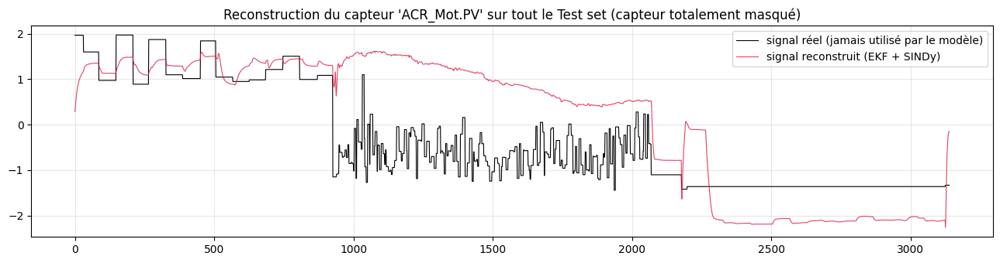

RMSE (échelle standardisée) : 1.1296   |  std du signal réel : 1.1177


In [22]:
def reconstruct_missing_sensor(Y_test_others, x0=None):
    '''Y_test_others : (N, n_other_sensors) valeurs (scalées) des capteurs disponibles sur la fenêtre de test.
    Retourne y_hat (N,) reconstruction du capteur cible (échelle réduite/scaled).'''
    if x0 is None:
        # initialisation par projection (méthode SSI classique) sur les tout premiers points
        x0 = ssi_estimate_states(Y_test_others[:SSI_BLOCK_ROWS], C_obs_full, A, min(SSI_BLOCK_ROWS, len(Y_test_others)))[0] \
             if len(Y_test_others) >= SSI_BLOCK_ROWS else np.zeros(SSI_ORDER)
    X_hat = run_ekf(Y_test_others, C_obs_full, x0)
    y_hat = X_hat @ C_target_row.T
    return y_hat.ravel(), X_hat

Y_test_others = test_s[selected_sensors].values
y_test_true   = test_s[TARGET_SENSOR].values

# Démonstration : masquage complet du capteur cible sur TOUT le test set
y_hat_demo, X_hat_demo = reconstruct_missing_sensor(Y_test_others)

fig, ax = plt.subplots(figsize=(13,3.5))
ax.plot(y_test_true, label="signal réel (jamais utilisé par le modèle)", color="black", lw=0.8)
ax.plot(y_hat_demo, label="signal reconstruit (EKF + SINDy)", color="crimson", lw=0.8, alpha=0.8)
ax.set_title(f"Reconstruction du capteur '{TARGET_SENSOR}' sur tout le Test set (capteur totalement masqué)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

rmse_demo = np.sqrt(np.mean((y_test_true - y_hat_demo)**2))
print(f"RMSE (échelle standardisée) : {rmse_demo:.4f}   |  std du signal réel : {y_test_true.std():.4f}")


In [23]:
from scipy.stats import pearsonr

def compute_metrics(y_true, y_hat, mask=None):
    '''mask : booléen, True = échantillon évalué (ex. uniquement la fenêtre masquée).'''
    if mask is not None:
        y_true = y_true[mask]
        y_hat = y_hat[mask]
    if len(y_true) < 2:
        return dict(MAE=np.nan, RMSE=np.nan, R2=np.nan, Corr=np.nan)
    mae = np.mean(np.abs(y_true - y_hat))
    rmse = np.sqrt(np.mean((y_true - y_hat)**2))
    ss_res = np.sum((y_true - y_hat)**2)
    ss_tot = np.sum((y_true - y_true.mean())**2)
    r2 = 1 - ss_res/ss_tot if ss_tot > 0 else np.nan
    corr = pearsonr(y_true, y_hat)[0] if np.std(y_true) > 0 and np.std(y_hat) > 0 else np.nan
    return dict(MAE=mae, RMSE=rmse, R2=r2, Corr=corr)

print("compute_metrics() prêt.")


compute_metrics() prêt.


## 9. Évaluer dans des situations réalistes

On teste : quelques points absents, une longue coupure, et les zones de pics. Les pics sont importants car ils portent souvent l'information vibratoire la plus forte.


⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5704
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. M

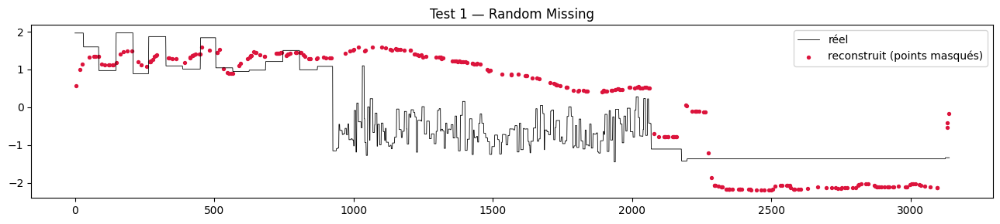

In [24]:
rng = np.random.default_rng(RANDOM_SEED)
n_test = len(y_test_true)
random_mask = rng.random(n_test) < RANDOM_MISSING_FRACTION   # True = échantillon masqué à reconstruire

y_test_others_random = Y_test_others.copy()
# on garde toujours les AUTRES capteurs disponibles (seul le capteur cible est masqué, comme précisé dans l'énoncé)
y_hat_random, _ = reconstruct_missing_sensor(y_test_others_random)

metrics_random = compute_metrics(y_test_true, y_hat_random, mask=random_mask)
print(f"Random Missing ({RANDOM_MISSING_FRACTION:.0%} des points) — évalué uniquement sur les points masqués :")
for k, v in metrics_random.items():
    print(f"  {k}: {v:.4f}")

fig, ax = plt.subplots(figsize=(13,3))
ax.plot(y_test_true, color="black", lw=0.6, label="réel")
ax.scatter(np.where(random_mask)[0], y_hat_random[random_mask], color="crimson", s=8, label="reconstruit (points masqués)")
ax.legend(); ax.set_title("Test 1 — Random Missing")
plt.tight_layout(); plt.show()


In [ ]:
continuous_results = []
continuous_curves = {}

for frac in CONTINUOUS_WINDOW_FRACTIONS:
    win_len = max(5, int(frac * n_test))
    start = 350  # fenêtre centrée dans le test set
    end = start + win_len
    mask = np.zeros(n_test, dtype=bool)
    mask[start:end] = True

    # Reconstruction sur toute la séquence de test (l'observateur tourne en continu ;
    # seule la fenêtre [start,end) est ensuite évaluée -> le vrai signal cible n'est
    # jamais injecté dans le modèle, y compris hors fenêtre)
    y_hat_win, _ = reconstruct_missing_sensor(Y_test_others)
    m = compute_metrics(y_test_true, y_hat_win, mask=mask)
    m["window_frac"] = frac
    m["window_len"] = win_len
    continuous_results.append(m)
    continuous_curves[frac] = (start, end, y_hat_win)

df_continuous = pd.DataFrame(continuous_results)
print(df_continuous[["window_frac","window_len","MAE","RMSE","R2","Corr"]])
df_continuous.to_csv(os.path.join(OUTPUT_DIR, "test2_continuous_window_missing.csv"), index=False)


⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5704
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 5.5703
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. Max = 6.0556
⚠️ SINDy : 1 états hors domaine. M

In [ ]:
peaks_test, _ = find_peaks(y_test_true, prominence=np.std(y_test_true)*1.0)
print(f"{len(peaks_test)} pics détectés sur le capteur cible (Test).")

peak_mask = np.zeros(n_test, dtype=bool)
for p in peaks_test:
    lo = max(0, p - PEAK_WINDOW_HALF_WIDTH)
    hi = min(n_test, p + PEAK_WINDOW_HALF_WIDTH)
    peak_mask[lo:hi] = True

y_hat_peaks, _ = reconstruct_missing_sensor(Y_test_others)
metrics_peaks = compute_metrics(y_test_true, y_hat_peaks, mask=peak_mask)
print("Métriques globales sur les régions de pics :")
for k, v in metrics_peaks.items():
    print(f"  {k}: {v:.4f}")

# erreur d'amplitude et de position par pic individuel
amp_errors, pos_errors = [], []
for p in peaks_test:
    lo = max(0, p - PEAK_WINDOW_HALF_WIDTH)
    hi = min(n_test, p + PEAK_WINDOW_HALF_WIDTH)
    true_local = y_test_true[lo:hi]
    hat_local = y_hat_peaks[lo:hi]
    amp_errors.append(abs(true_local.max() - hat_local.max()))
    pos_errors.append(abs(np.argmax(true_local) - np.argmax(hat_local)))

print(f"\nErreur moyenne d'amplitude de pic : {np.mean(amp_errors):.4f}")
print(f"Erreur moyenne de position de pic (échantillons) : {np.mean(pos_errors):.2f}")

fig, ax = plt.subplots(figsize=(13,3.5))
ax.plot(y_test_true, color="black", lw=0.6, label="réel")
ax.plot(y_hat_peaks, color="crimson", lw=0.6, alpha=0.6, label="reconstruit")
ax.scatter(peaks_test, y_test_true[peaks_test], color="blue", s=15, zorder=5, label="pics détectés")
ax.set_title("Test 3 — Peak Missing : reconstruction autour des pics")
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:
ACCEPTABLE_NRMSE_THRESHOLD = 0.5   # RMSE / std(signal) -- seuil arbitraire mais explicite, à ajuster selon l'application

long_window_results = []
fig, axes = plt.subplots(len(LONG_WINDOW_FRACTIONS), 1, figsize=(13, 3*len(LONG_WINDOW_FRACTIONS)))
if len(LONG_WINDOW_FRACTIONS) == 1:
    axes = [axes]

for ax, frac in zip(axes, LONG_WINDOW_FRACTIONS):
    win_len = max(10, int(frac * n_test))
    start = (n_test - win_len) // 2
    end = start + win_len
    y_hat_long, _ = reconstruct_missing_sensor(Y_test_others)
    e_t = y_test_true[start:end] - y_hat_long[start:end]
    nrmse_running = np.sqrt(np.cumsum(e_t**2) / (np.arange(1, len(e_t)+1))) / y_test_true.std()

    ax.plot(e_t, color="darkred", lw=0.8)
    ax.set_title(f"Erreur e(t) sur fenêtre longue ({frac:.0%} du Test, {win_len} échantillons)")
    ax.axhline(0, color="black", lw=0.5)
    ax.grid(alpha=0.3)

    exceed_idx = np.where(nrmse_running > ACCEPTABLE_NRMSE_THRESHOLD)[0]
    max_acceptable = exceed_idx[0] if len(exceed_idx) > 0 else win_len
    long_window_results.append(dict(window_frac=frac, window_len=win_len,
                                     max_acceptable_samples=max_acceptable,
                                     final_nrmse=nrmse_running[-1]))

plt.tight_layout()
plt.show()

df_long = pd.DataFrame(long_window_results)
print(df_long)
df_long.to_csv(os.path.join(OUTPUT_DIR, "test4_long_missing_window.csv"), index=False)
print(f"\nSeuil NRMSE acceptable fixé à {ACCEPTABLE_NRMSE_THRESHOLD} (RMSE/std). "
      f"'max_acceptable_samples' = nb d'échantillons avant que l'erreur cumulée dépasse ce seuil.")


## 10. Comparer avec des repères simples

Les méthodes simples disent si le pipeline dynamique apporte vraiment quelque chose : interpolation, régression, PCA et SSI+Kalman sans SINDy.


In [ ]:
# --- Baseline 1 : interpolation temporelle ---
def baseline_interpolation(y_true, mask):
    y_masked = y_true.copy()
    y_masked[mask] = np.nan
    y_hat = pd.Series(y_masked).interpolate(method="linear", limit_direction="both").values
    return y_hat

# --- Baseline 2 : régression multivariée (Train) ---
from sklearn.linear_model import LinearRegression
reg_model = LinearRegression()
reg_model.fit(train_s[selected_sensors].values, train_s[TARGET_SENSOR].values)

def baseline_regression(Y_others):
    return reg_model.predict(Y_others)

# --- Baseline 3 : reconstruction PCA (Train, incluant la cible) ---
from sklearn.decomposition import PCA
PCA_N_COMPONENTS = min(len(ALL_SSI_SENSORS), max(2, SSI_ORDER))
pca_model = PCA(n_components=PCA_N_COMPONENTS)
pca_model.fit(train_s[ALL_SSI_SENSORS].values)   # colonnes = [TARGET_SENSOR] + selected_sensors

def baseline_pca(Y_others):
    '''Reconstruit la cible en résolvant, dans le sous-espace PCA, les scores compatibles
    avec les capteurs disponibles uniquement, puis en reconstruisant la composante cible.'''
    components = pca_model.components_               # (k, m_all)
    mean_ = pca_model.mean_
    idx_target = 0                                     # TARGET_SENSOR est en 1ère colonne de ALL_SSI_SENSORS
    idx_others = list(range(1, len(ALL_SSI_SENSORS)))
    W_others = components[:, idx_others]               # (k, m_other)
    mean_others = mean_[idx_others]
    # scores = argmin || W_others^T s - (y_others - mean_others) ||  (moindres carrés)
    scores, *_ = np.linalg.lstsq(W_others.T, (Y_others - mean_others).T, rcond=None)
    y_hat = (components[:, idx_target] @ scores) + mean_[idx_target]
    return y_hat

# --- Baseline 4 : SSI + Kalman SANS SINDy (dynamique linéaire discrète brute) ---
def f_linear(x):
    '''Approxime la dynamique continue équivalente à x_{k+1}=Ax_k : dx/dt = (A - I)/dt * x'''
    return (A - np.eye(SSI_ORDER)) @ x / DT_APPROX

def baseline_ssi_kalman_no_sindy(Y_others, x0=None):
    if x0 is None:
        x0 = ssi_estimate_states(Y_others[:SSI_BLOCK_ROWS], C_obs_full, A, min(SSI_BLOCK_ROWS, len(Y_others)))[0] \
             if len(Y_others) >= SSI_BLOCK_ROWS else np.zeros(SSI_ORDER)
    Q = EKF_Q_SCALE * np.eye(SSI_ORDER)
    R = EKF_R_SCALE * np.eye(Y_others.shape[1])
    ekf_lin = ExtendedKalmanFilter(f_linear, C_obs_full, Q, R, DT_APPROX)
    x = x0.copy(); P = 0.1*np.eye(SSI_ORDER)
    X_hat = np.zeros((len(Y_others), SSI_ORDER))
    for k in range(len(Y_others)):
        x, P = ekf_lin.step(x, P, Y_others[k])
        X_hat[k] = x
    return (X_hat @ C_target_row.T).ravel()

print("Baselines définies : interpolation, régression, PCA, SSI+Kalman (sans SINDy).")


In [ ]:
mid_frac = CONTINUOUS_WINDOW_FRACTIONS[len(CONTINUOUS_WINDOW_FRACTIONS)//2]
win_len_main = max(5, int(mid_frac * n_test))
start_main = (n_test - win_len_main) // 2
end_main = start_main + win_len_main
main_mask = np.zeros(n_test, dtype=bool)
main_mask[start_main:end_main] = True

y_hat_interp = baseline_interpolation(y_test_true, main_mask)
y_hat_reg    = baseline_regression(Y_test_others)
y_hat_pca    = baseline_pca(Y_test_others)
y_hat_ssikf  = baseline_ssi_kalman_no_sindy(Y_test_others)
y_hat_proposed, _ = reconstruct_missing_sensor(Y_test_others)

methods = {
    "Interpolation": y_hat_interp,
    "Régression multivariée": y_hat_reg,
    "PCA": y_hat_pca,
    "SSI + Kalman (sans SINDy)": y_hat_ssikf,
    "SSI + SINDy + Kalman (proposée)": y_hat_proposed,
}

rows = []
for name, y_hat in methods.items():
    m_win = compute_metrics(y_test_true, y_hat, mask=main_mask)
    m_peak = compute_metrics(y_test_true, y_hat, mask=peak_mask)
    rows.append(dict(Method=name, MAE=m_win["MAE"], RMSE=m_win["RMSE"], R2=m_win["R2"],
                      Correlation=m_win["Corr"], Peak_RMSE=m_peak["RMSE"]))

df_comparison = pd.DataFrame(rows).set_index("Method").round(4)
df_comparison.to_csv(os.path.join(OUTPUT_DIR, "comparison_table.csv"))
df_comparison


In [ ]:
# Résultats par longueur de fenêtre pour la méthode proposée ET pour SSI+Kalman sans SINDy (comparaison)
rows_by_len = []
for frac in CONTINUOUS_WINDOW_FRACTIONS:
    win_len = max(5, int(frac * n_test))
    start = (n_test - win_len) // 2
    end = start + win_len
    mask = np.zeros(n_test, dtype=bool); mask[start:end] = True

    y_hat_prop, _ = reconstruct_missing_sensor(Y_test_others)
    y_hat_lin = baseline_ssi_kalman_no_sindy(Y_test_others)

    m_prop = compute_metrics(y_test_true, y_hat_prop, mask=mask)
    m_lin  = compute_metrics(y_test_true, y_hat_lin, mask=mask)
    rows_by_len.append(dict(window_frac=frac, RMSE_proposed=m_prop["RMSE"], RMSE_ssi_kalman=m_lin["RMSE"]))

df_by_len = pd.DataFrame(rows_by_len)
df_by_len.to_csv(os.path.join(OUTPUT_DIR, "rmse_by_window_length.csv"), index=False)

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(df_by_len["window_frac"]*100, df_by_len["RMSE_proposed"], "o-", label="SSI+SINDy+Kalman", color="crimson")
ax.plot(df_by_len["window_frac"]*100, df_by_len["RMSE_ssi_kalman"], "s--", label="SSI+Kalman (sans SINDy)", color="steelblue")
ax.set_xlabel("Longueur de la fenêtre manquante (% du Test)")
ax.set_ylabel("RMSE")
ax.legend()
ax.set_title("RMSE vs longueur de fenêtre — méthode proposée vs baseline SSI+Kalman")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
df_by_len


## 11. Peut-on observer l'état caché ?

Un rang complet signifie que les autres capteurs contiennent, en théorie, assez d'information pour suivre l'état. Une matrice mal conditionnée signifie néanmoins que le bruit peut fortement perturber l'estimation.


In [ ]:
def observability_matrix(C_mat, A_mat, n_blocks=None):
    n = A_mat.shape[0]
    n_blocks = n_blocks or n
    blocks = [C_mat]
    Ak = np.eye(n)
    for _ in range(1, n_blocks):
        Ak = Ak @ A_mat
        blocks.append(C_mat @ Ak)
    return np.vstack(blocks)

O_full = observability_matrix(C_ssi, A)          # avec le capteur cible inclus
O_obs  = observability_matrix(C_obs_full, A)      # sans le capteur cible (cas réel de reconstruction)

rank_full = np.linalg.matrix_rank(O_full)
rank_obs  = np.linalg.matrix_rank(O_obs)
cond_full = np.linalg.cond(O_full)
cond_obs  = np.linalg.cond(O_obs)

print(f"Ordre de l'état latent n = {SSI_ORDER}")
print(f"\nAvec TOUS les capteurs (y compris cible)   : rang = {rank_full}/{SSI_ORDER}, cond = {cond_full:.2e}")
print(f"Avec les SEULS capteurs disponibles (réel) : rang = {rank_obs}/{SSI_ORDER}, cond = {cond_obs:.2e}")

if rank_obs < SSI_ORDER:
    print("\n[ATTENTION] Le système N'EST PAS pleinement observable une fois le capteur cible retiré.")
    print("            Certaines directions de l'état latent ne peuvent pas être estimées de façon fiable ;")
    print("            la reconstruction du capteur manquant peut devenir instable ou biaisée sur ces directions.")
else:
    print("\n[OK] Le système reste observable avec les seuls capteurs disponibles.")
    if cond_obs > 10 * cond_full:
        print("      Le conditionnement se dégrade cependant nettement -> observabilité 'faible' en pratique")
        print("      (sensibilité accrue au bruit de mesure malgré un rang plein).")


## Conclusion de recherche — à lire avec les résultats affichés

**Ce qui avance :** la présence de capteurs corrélés et l'observabilité montrent que la dynamique commune peut être déduite en partie à partir des autres mesures. Les métriques RMSE, R², corrélation et stabilité indiquent jusqu'où la reconstruction est utilisable.

**La limite importante :** une bonne forme, une meilleure variance ou un meilleur R² ne prouvent pas que l'amplitude est juste. Vérifier aussi le rapport d'écart-type, l'erreur sur les pics et la comparaison visuelle. Si les amplitudes restent trop petites ou trop grandes, le modèle n'a pas encore appris l'atténuation physique liée à la matière, à la distance et aux conditions de montage.

**Prochaine étude :** analyser séparément les amplitudes et les pics : normalisation par régime de fonctionnement, variables de distance/matière si disponibles, transfert fréquentiel entre capteurs, ou modèle qui prédit explicitement le gain d'amplitude. Le résultat actuel est donc une base dynamique, pas encore une reconstruction d'amplitude validée.
